<a href="https://colab.research.google.com/github/karimabouazzabouazza-crypto/L-NEER-CEB-R-/blob/main/Parkinson_Makine_Ogrenmesi_Projesi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Parkinson Ses Verileri ile Makine Öğrenmesi Sınıflandırma Projesi

**Amaç:** UCI Machine Learning Repository'deki Parkinson ses ölçümleri veri setini kullanarak `status` sütununu tahmin eden sınıflandırma modelleri kurmak.

> **Önemli:** Bu çalışma eğitim amaçlıdır. Tıbbi tanı koymaz ve gerçek sağlık kararlarında kullanılamaz.

## Veri seti hakkında
UCI kaynağındaki Oxford Parkinson's Disease Detection Dataset, 31 kişiden alınan 195 ses kaydını ve biyomedikal ses ölçümlerini içerir. `status` hedef sütununda `1` Parkinson hastalığı grubunu, `0` sağlıklı kontrol grubunu belirtir. Veri kaynağı ve atıf bilgisi:
- https://archive.ics.uci.edu/dataset/174/parkinsons
- Little, M. (2007). *Parkinsons*. UCI Machine Learning Repository. https://doi.org/10.24432/C59C74

Bu veri seti küçük ve belirli bir örneklemden oluştuğu için sonuçlar genellenebilir klinik performans olarak yorumlanmamalıdır.


## 1. Gerekli kütüphaneler

Aşağıdaki hücre, veri analizi, görselleştirme ve makine öğrenmesi için gerekli paketleri yükler.

In [ ]:
!pip -q install ucimlrepo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

RANDOM_STATE = 42
print("Kütüphaneler hazır.")

Kütüphaneler hazır.


## 2. Veri setini yükleme

Veri, UCI kaynağından `ucimlrepo` paketiyle alınır. İnternet bağlantısı gerekir.

In [ ]:
dataset = fetch_ucirepo(id=174)

X = dataset.data.features.copy()
y = dataset.data.targets.copy()

# Hedef sütununu tek boyutlu hale getir
if isinstance(y, pd.DataFrame):
    y = y.iloc[:, 0]

print("Özellik boyutu:", X.shape)
print("Hedef boyutu:", y.shape)
display(X.head())

Özellik boyutu: (195, 22)
Hedef boyutu: (195,)


,MDVP:Fo,MDVP:Fhi,MDVP:Flo,MDVP:Jitter,MDVP:Jitter,MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer,...,MDVP:APQ,Shimmer:DDA,NHR,HNR,RPDE,DFA,spread1,spread2,D2,PPE
0,119.992,157.302,74.997,0.00784,0.00784,0.00370,0.00554,0.01109,0.04374,0.04374,...,0.02971,0.06545,0.02211,21.033,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,122.400,148.650,113.819,0.00968,0.00968,0.00465,0.00696,0.01394,0.06134,0.06134,...,0.04368,0.09403,0.01929,19.085,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,116.682,131.111,111.555,0.01050,0.01050,0.00544,0.00781,0.01633,0.05233,0.05233,...,0.03590,0.08270,0.01309,20.651,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,116.676,137.871,111.366,0.00997,0.00997,0.00502,0.00698,0.01505,0.05492,0.05492,...,0.03772,0.08771,0.01353,20.644,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,116.014,141.781,110.655,0.01284,0.01284,0.00655,0.00908,0.01966,0.06425,0.06425,...,0.04465,0.10470,0.01767,19.649,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335


## 3. Veriyi tanıma ve kontrol etme

Sütun türleri, eksik değerler ve hedef sınıf dağılımı incelenir.

In [ ]:
display(X.info())
display(X.describe().T)
print("Eksik değer sayıları:")
display(X.isnull().sum())
print("Hedef sınıf dağılımı:")
display(y.value_counts().sort_index())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 195 entries, 0 to 194
Data columns (total 22 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   MDVP:Fo       195 non-null    float64
 1   MDVP:Fhi      195 non-null    float64
 2   MDVP:Flo      195 non-null    float64
 3   MDVP:Jitter   195 non-null    float64
 4   MDVP:Jitter   195 non-null    float64
 5   MDVP:RAP      195 non-null    float64
 6   MDVP:PPQ      195 non-null    float64
 7   Jitter:DDP    195 non-null    float64
 8   MDVP:Shimmer  195 non-null    float64
 9   MDVP:Shimmer  195 non-null    float64
 10  Shimmer:APQ3  195 non-null    float64
 11  Shimmer:APQ5  195 non-null    float64
 12  MDVP:APQ      195 non-null    float64
 13  Shimmer:DDA   195 non-null    float64
 14  NHR           195 non-null    float64
 15  HNR           195 non-null    float64
 16  RPDE          195 non-null    float64
 17  DFA           195 non-null    float64
 18  spread1       195 non-null    

None

,count,mean,std,min,25%,50%,75%,max
MDVP:Fo,195.0,154.228641,41.390065,88.333000,117.572000,148.790000,182.769000,260.105000
MDVP:Fhi,195.0,197.104918,91.491548,102.145000,134.862500,175.829000,224.205500,592.030000
MDVP:Flo,195.0,116.324631,43.521413,65.476000,84.291000,104.315000,140.018500,239.170000
MDVP:Jitter,195.0,0.006220,0.004848,0.001680,0.003460,0.004940,0.007365,0.033160
MDVP:Jitter,195.0,0.006220,0.004848,0.001680,0.003460,0.004940,0.007365,0.033160
MDVP:RAP,195.0,0.003306,0.002968,0.000680,0.001660,0.002500,0.003835,0.021440
MDVP:PPQ,195.0,0.003446,0.002759,0.000920,0.001860,0.002690,0.003955,0.019580
Jitter:DDP,195.0,0.009920,0.008903,0.002040,0.004985,0.007490,0.011505,0.064330
MDVP:Shimmer,195.0,0.029709,0.018857,0.009540,0.016505,0.022970,0.037885,0.119080
MDVP:Shimmer,195.0,0.029709,0.018857,0.009540,0.016505,0.022970,0.037885,0.119080


Eksik değer sayıları:


,0
MDVP:Fo,0
MDVP:Fhi,0
MDVP:Flo,0
MDVP:Jitter,0
MDVP:Jitter,0
MDVP:RAP,0
MDVP:PPQ,0
Jitter:DDP,0
MDVP:Shimmer,0
MDVP:Shimmer,0


Hedef sınıf dağılımı:


,count
status,
0,48
1,147


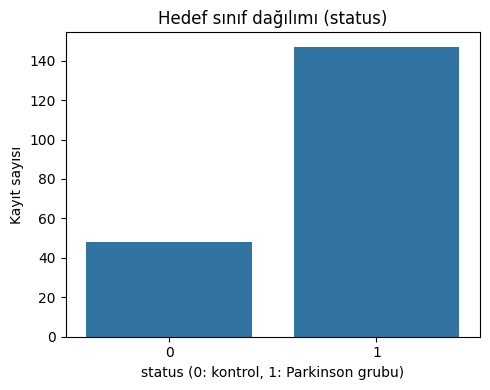

In [ ]:
plt.figure(figsize=(5, 4))
sns.countplot(x=y)
plt.title("Hedef sınıf dağılımı (status)")
plt.xlabel("status (0: kontrol, 1: Parkinson grubu)")
plt.ylabel("Kayıt sayısı")
plt.tight_layout()
plt.show()

## 4. Veri hazırlama ve eğitim/test ayırma

`name` sütunu kişi/kayıt kimliği olduğu için model özelliği olarak kullanılmaz. Sayısal ses ölçümleri kullanılır. Veri, sınıf oranlarını koruyacak şekilde eğitim ve test kümelerine ayrılır.

In [ ]:
X_model = X.copy()

# Kimlik sütununu varsa çıkar
if "name" in X_model.columns:
    X_model = X_model.drop(columns=["name"])

# Sayısal olmayan sütunları çıkar; bu veri setinde ölçümler sayısaldır
X_model = X_model.select_dtypes(include=[np.number])

X_train, X_test, y_train, y_test = train_test_split(
    X_model, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Eğitim:", X_train.shape)
print("Test:", X_test.shape)

Eğitim: (156, 22)
Test: (39, 22)


## 5. Modelleri eğitme ve karşılaştırma

Üç sınıflandırma modeli denenir:
- Lojistik Regresyon
- Destek Vektör Makineleri (SVM)
- Rastgele Orman (Random Forest)

Ölçeklendirme gereken modellerde `StandardScaler`, veri sızıntısını önlemek için `Pipeline` içinde kullanılır.

In [ ]:
models = {
    "Lojistik Regresyon": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))
    ]),
    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(class_weight="balanced"))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300, random_state=RANDOM_STATE,
            class_weight="balanced"
        ))
    ])
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values("F1-score", ascending=False)
display(results_df)

,Model,Accuracy,Precision,Recall,F1-score
2,Random Forest,0.923077,0.933333,0.965517,0.949153
1,SVM,0.794872,1.000000,0.724138,0.840000
0,Lojistik Regresyon,0.769231,0.954545,0.724138,0.823529


## 6. En iyi modelin ayrıntılı değerlendirmesi

Bu bölümde test kümesinde F1-score değeri en yüksek çıkan modelin sınıflandırma raporu ve karmaşıklık matrisi gösterilir.

Seçilen model: Random Forest
              precision    recall  f1-score   support

           0       0.89      0.80      0.84        10
           1       0.93      0.97      0.95        29

    accuracy                           0.92        39
   macro avg       0.91      0.88      0.90        39
weighted avg       0.92      0.92      0.92        39



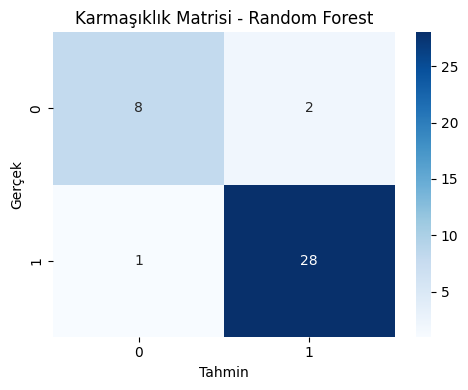

In [ ]:
best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]
best_predictions = best_model.predict(X_test)

print("Seçilen model:", best_name)
print(classification_report(y_test, best_predictions, zero_division=0))

cm = confusion_matrix(y_test, best_predictions)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title(f"Karmaşıklık Matrisi - {best_name}")
plt.xlabel("Tahmin")
plt.ylabel("Gerçek")
plt.tight_layout()
plt.show()

## 7. Sonuçları yorumlama

Aşağıdaki hücre, model karşılaştırma tablosunu yeniden gösterir. Rapor yazarken yalnızca burada elde ettiğiniz gerçek değerleri kullanın.

- **Accuracy:** Tüm tahminlerin ne kadarının doğru olduğunu gösterir.
- **Precision:** Modelin pozitif dediği kayıtların ne kadarının gerçekten pozitif olduğunu gösterir.
- **Recall:** Gerçek pozitif kayıtların ne kadarının yakalandığını gösterir.
- **F1-score:** Precision ve Recall değerlerini birlikte özetler.

**Dikkat edilmesi gereken sınırlılık:** Aynı kişiden birden fazla ses kaydı bulunduğundan, rastgele kayıt bazlı eğitim/test ayrımı aynı kişiye ait kayıtları iki kümeye de koyabilir. Bu durum performansın olduğundan yüksek görünmesine yol açabilir. Bu nedenle sonuçlar dikkatli yorumlanmalıdır. Daha ileri bir çalışmada kişi bazlı grup ayırma (Group split) tercih edilebilir.

## 8. Proje sonuç özeti

Aşağıdaki hücre, rapora aktarabilmeniz için en iyi modelin metriklerini yazdırır.

In [ ]:
best_row = results_df.iloc[0]
print(f"En yüksek F1-score değerine sahip model: {best_row['Model']}")
print(f"Accuracy : {best_row['Accuracy']:.3f}")
print(f"Precision: {best_row['Precision']:.3f}")
print(f"Recall   : {best_row['Recall']:.3f}")
print(f"F1-score : {best_row['F1-score']:.3f}")

print("\nGenel değerlendirme:")
print("Bu proje, ses ölçümlerinden yararlanarak sınıflandırma modellerinin")
print("eğitim ve test performansını karşılaştırmıştır. Bu sonuçlar tıbbi tanı değildir.")

En yüksek F1-score değerine sahip model: Random Forest
Accuracy : 0.923
Precision: 0.933
Recall   : 0.966
F1-score : 0.949

Genel değerlendirme:
Bu proje, ses ölçümlerinden yararlanarak sınıflandırma modellerinin
eğitim ve test performansını karşılaştırmıştır. Bu sonuçlar tıbbi tanı değildir.


## Kaynakça

Little, M. (2007). *Parkinsons*. UCI Machine Learning Repository. https://doi.org/10.24432/C59C74

UCI veri seti sayfası: https://archive.ics.uci.edu/dataset/174/parkinsons
